In [1]:
import warnings
from copy import deepcopy
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# The pipeline lives in main2.py so the script and the notebook cannot drift.
# Run `python main2.py` to regenerate everything below, or set the RUN_ flag to
# drive it from here.
from main2 import (
    ERRORS_PATH,
    LABELS,
    METHODS,
    METHOD_COLORS,
    RESULTS_DIR,
    kappa_by_support,
    make_config,
    run_monte_carlo,
    run_trajectories,
    weak_design,
)
from mfsindy.plots import bubble_hist

warnings.filterwarnings("ignore")
sns.set(context="paper", style="white")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

cfg = make_config()


# Lorenz Part 2 — Intra-trajectory GLS

This notebook compares four weightings of the weak SINDy regression on short
trajectories whose noise varies along each of them. They form a 2x2 over what the weak
covariance is allowed to carry:

- *No weighting* -- ordinary least squares on the weak system (`WeakPDELibrary`);
- *Ones GLS* -- the correlations between overlapping test functions only, as if
  the noise were constant (`WeightedWeakPDELibrary`, unit variance);
- *Variance diag* -- each weak equation weighted by its own variance, the
  correlations dropped (`whitener_mode="diag"`);
- *Variance GLS* -- the full weak covariance, variances and correlations
  together (`WeightedWeakPDELibrary`, pointwise variance).

All four are fitted on the same test functions, support and threshold, so a
difference between them is the weighting alone.


## Governing equations

The classical Lorenz--63 system is given by

$$
\begin{aligned}
\dot{x} &= \sigma (y - x), \\
\dot{y} &= x(\rho - z) - y, \\
\dot{z} &= xy - \beta z.
\end{aligned}
$$

We use the standard parameter values $(\sigma, \rho, \beta) = (10, 28, 8/3)$.

Each state component is measured with its own noise: additive, zero-mean and
Gaussian, independent between samples and between components, with standard
deviation following the two-component measurement-error model -- an absolute
floor plus an error proportional to the reading:
$$
x_i^{\mathrm{noisy}}(t) = x_i(t) + \epsilon_i(t), \qquad
\epsilon_i(t) \sim \mathcal{N}\big(0, \sigma_i(t)^2\big), \qquad
\sigma_i(t) = a\, s_i + b\, |x_i(t)|,
$$
with $b = 0.15$, $a = 10^{-4}$ and $s_i$ the spread of component $i$ along the
trajectory. Each component is quiet where it crosses zero and loud where it is
large, so the quiet stretches differ between components; each equation is
therefore whitened with its own component's noise.

Each Monte Carlo run draws `cfg.n_traj` = 10 trajectories, each over $T = 1$ at
$\Delta t = 10^{-3}$, from starting points uniform on $[-20, 20]^3$. Every trajectory is whitened
with its own covariance and the weak systems are stacked (the noise is
independent between trajectories), on the same test functions for every
weighting.


## Trajectories

The trajectories of the first Monte Carlo run, exactly as it draws and fits them:
clean paths, noisy samples and starting points.

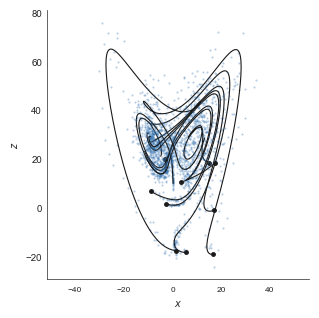

In [2]:
from mfsindy.cases.lorenz import LORENZ_STATE_NAMES
from mfsindy.plots import plot_run_trajectories, plot_state_noise

t, clean, noisy, variance = run_trajectories(cfg, run_idx=0)
plot_run_trajectories(clean, noisy, dims=(0, 2), state_names=LORENZ_STATE_NAMES,
                      save_path="results/trajectories_2")


Each component of the run's first trajectory against time: the clean signal, the
noisy samples, and a band of $\pm 2\sigma_i$ for that component's noise. Each
component is quiet where it crosses zero and loud where it is large, so the quiet
stretches differ from one component to the next -- which is why each equation is
whitened with its own component's noise.

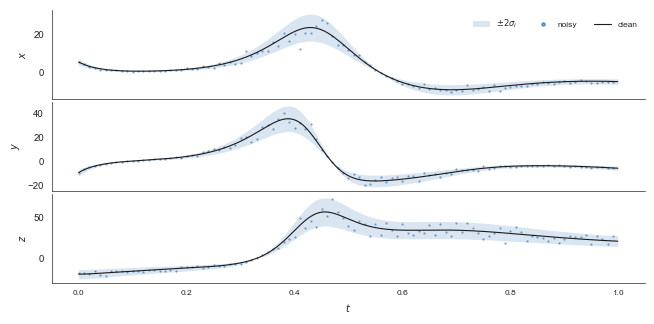

In [3]:
j = 0                                    # which of the run's trajectories
plot_state_noise(t - t[0], clean[j], noisy[j], np.sqrt(variance[j]),
                 state_names=LORENZ_STATE_NAMES, save_path="results/states_2")


## Selection protocol

Every weighting goes through the same procedure, with no true coefficients: the
threshold is chosen per equation by BIC inside the ensemble, and the support is
the candidate in `H_grid` (`supports(cfg)` in `main2.py`) at which the
weighting's bagged least-squares coefficients, before thresholding, are
tightest, among the supports whose weak system has at least twice as many rows
as library terms. The tables give the weak design
and $\kappa$ at every candidate support; $\kappa$ is defined at the true
coefficients, so it describes the candidates and chooses nothing.

In [4]:
kappa_table = kappa_by_support(cfg, verbose=False)
print(kappa_table.drop(columns=[c for c in ("kappa_min", "kappa_max") if c in kappa_table]).round(3).to_string(index=False))


 H_xt   K  kappa_median
0.005 176         0.002
0.010  95         0.009
0.020  47         0.032
0.050  20         0.215
0.100  10         0.908
0.200   5         4.497


## Run

In [5]:
# Set to True to run the Monte Carlo here; leave False to read what main2.py
# wrote. Running it overwrites the CSV below.
RUN_EXPERIMENT = False

if RUN_EXPERIMENT:
    run_monte_carlo(cfg)


## Errors

In [6]:
df_errors = pd.read_csv(ERRORS_PATH)


def metric_values(metric: str) -> dict[str, np.ndarray]:
    return {
        m: df_errors[
            (df_errors["method"] == m) & (df_errors["metric"] == metric)
        ]["value"].to_numpy()
        for m in METHODS
    }


L1_errors = metric_values("L1")
L0_errors = metric_values("L0")

summary = pd.DataFrame(
    {
        "median L1": {m: float(np.median(L1_errors[m])) for m in METHODS},
        "median L0": {m: float(np.median(L0_errors[m])) for m in METHODS},
        "runs": {m: int(L1_errors[m].size) for m in METHODS},
    }
)
print(summary.to_string())


               median L1  median L0  runs
No weighting    0.055264   0.285714    25
Ones GLS        0.046488   0.142857    25
Variance diag   0.028955   0.000000    25
Variance GLS    0.029720   0.000000    25


### L1 Error

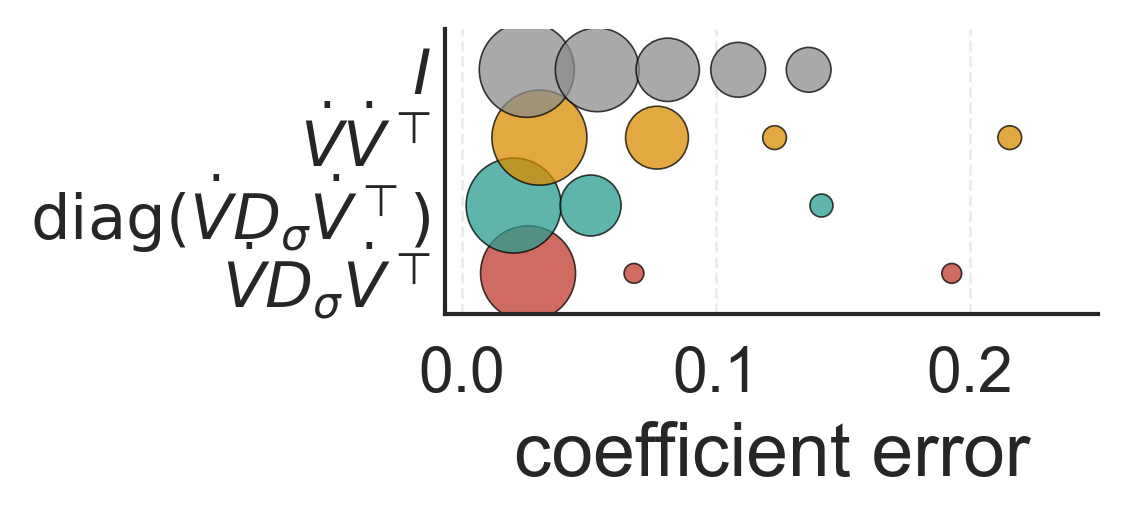

In [7]:
from mfsindy.plots import PART2_COLORS, bubble_hist

# Each row is binned over its own values on a log axis, since the models
# differ by orders of magnitude.
plot_order = list(reversed(METHODS))
bubble_hist(errors_dict=L1_errors, n_bins=5, models_order=plot_order,
            colors=PART2_COLORS, labels=[LABELS[m] for m in plot_order], xlabel="coefficient error",
            save_path="results/l1_2")


### L0 Error

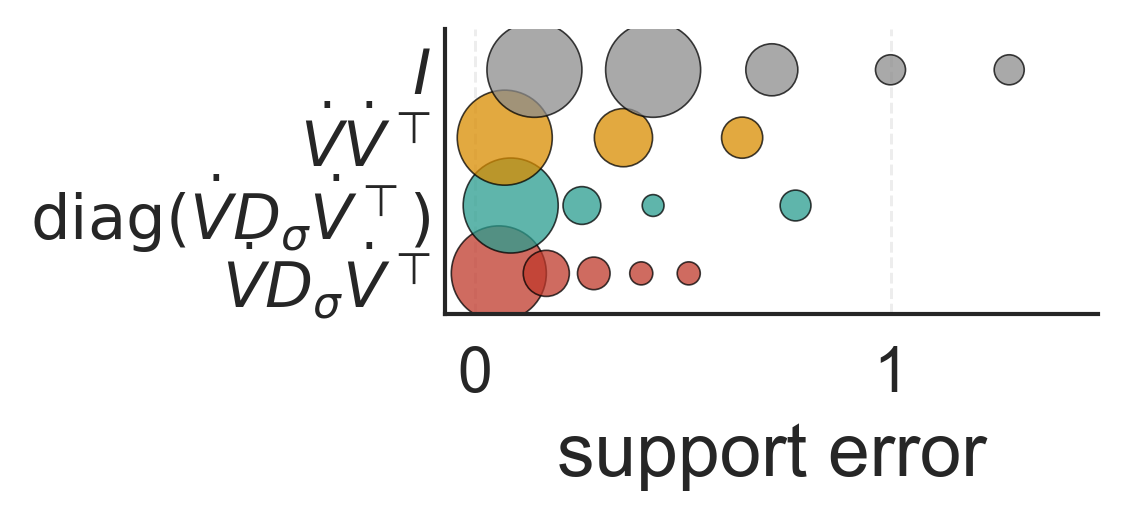

In [8]:
# Linear axis: support error is legitimately zero when a model recovers the
# true terms exactly, which a log axis cannot show.
all_l0 = np.concatenate([np.asarray(L0_errors[m], dtype=float) for m in plot_order])
pad = 0.05 * max(np.ptp(all_l0), 1.0)
bubble_hist(errors_dict=L0_errors, n_bins=5, models_order=plot_order, colors=PART2_COLORS,
            labels=[LABELS[m] for m in plot_order], xlim=(all_l0.min() - pad, all_l0.max() + pad),
            xlabel="support error", save_path="results/l0_2")


### Paired comparison

Run by run: the median of the error ratio Variance GLS / model (below 1: Variance GLS better), the share of runs Variance GLS wins, and the Wilcoxon signed-rank p-value of the paired difference.

In [9]:
from mfsindy.experiments import paired_comparison

print(paired_comparison(L1_errors, "Variance GLS").round(3).to_string())


               median ratio  reference wins  p (Wilcoxon)
model                                                    
No weighting          0.561            0.72         0.004
Ones GLS              0.650            0.68         0.016
Variance diag         0.993            0.52         0.916


## Hyperparameter selection (last run)

How each weighting chose, on the Monte Carlo's last run. Left: the spread of the
unthresholded bagged coefficients at every candidate support, the choice ringed. Then one
panel per equation: the weighting's fit-complexity front along its threshold path at
the chosen support, with the BIC choice ringed. BIC picks a point on this
Pareto front, with the trade-off between fit and number of terms fixed by
$\log N$; the support is chosen by the spread alone.

run 24, support chosen: {'No weighting': 0.2, 'Ones GLS': 0.2, 'Variance diag': 0.1, 'Variance GLS': 0.1}


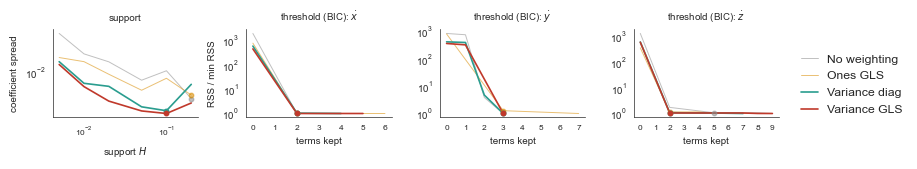

In [10]:
import pysindy as ps
from mfsindy.cases.lorenz import LORENZ_STATE_NAMES as STATE_NAMES

TERM_NAMES = ps.PolynomialLibrary(
    degree=cfg.poly_degree, include_bias=getattr(cfg, "include_bias", False)
).fit(np.zeros((2, len(STATE_NAMES)))).get_feature_names(list(STATE_NAMES))

from mfsindy.experiments import load_selection
from mfsindy.plots import PART2_COLORS, plot_coefficient_ensembles, plot_selection

record = load_selection(cfg)
print(f"run {record['run']}, support chosen:", {m: record['rungs'][m]['support'] for m in METHODS})
plot_selection(record, rungs=METHODS, colors=PART2_COLORS, equation_names=STATE_NAMES,
               save_path="results/selection_2")


## Threshold sweep (last run)

Everything behind the BIC choice: every threshold tried (relative to the largest
least-squares coefficient of the equation), with the number of terms the median
model keeps, its RSS relative to the weighting's best fit, and its BIC relative to the
minimum; the chosen threshold is filled. Each weighting is shown at the support it
chose. The panel above reduces the same sweep to its Pareto front.

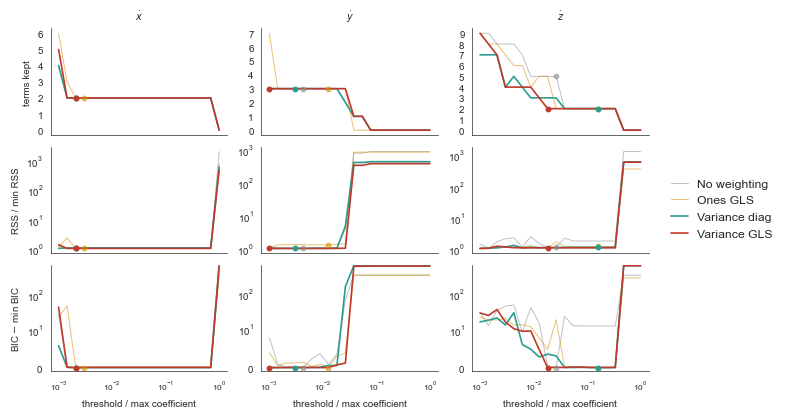

In [11]:
from mfsindy.plots import plot_threshold_path

plot_threshold_path(record, rungs=METHODS, colors=PART2_COLORS, equation_names=STATE_NAMES,
                    save_path="results/threshold_2")


## Ensemble coefficients (last run)

Every bagged model of every weighting, for each coefficient that is true or kept by
any weighting. The bar is the median, which is the reported coefficient; the dashed
line is the true value.

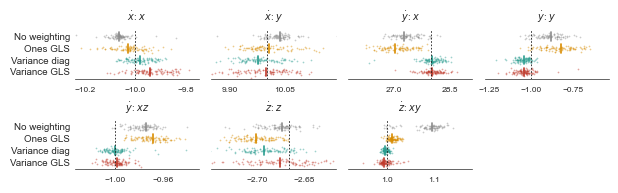

In [12]:
plot_coefficient_ensembles(record, rungs=METHODS, colors=PART2_COLORS,
                           row_names=TERM_NAMES, col_names=STATE_NAMES,
                           save_path="results/ensembles_2")


## Coefficients across runs

The coefficient every weighting reported on every Monte Carlo run, per true term: each
dot is one run, the tick the median over runs, the dashed line the true value. The
cloud is the estimator's sampling distribution -- its spread is the variance, its
offset from the true value the bias. Needs a Monte Carlo run with this version of
the code, which stores every run's coefficients.

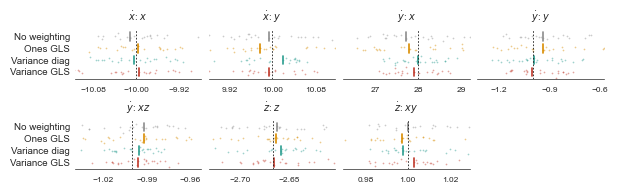

In [13]:
from mfsindy.plots import plot_coefficient_runs

plot_coefficient_runs(record, rungs=METHODS, colors=PART2_COLORS,
                      row_names=TERM_NAMES, col_names=STATE_NAMES,
                      save_path="results/coefficients_2")
